Original dataset shape: (4009, 12)
Cleaned dataset shape: (3983, 17)
Training set: 3186 samples | Test set: 797 samples

FINAL TEST EVALUATION RESULTS:
                               MAE ($)  RMSE ($)  R2 Score  MAPE (%)
Dummy Baseline (Mean)         24161.53  36300.91   -0.0013    124.04
Simple Linear (Mileage only)  19425.80  30556.03    0.2906     81.38
Ridge Regression (L2)         17658.43  29139.80    0.3548     67.45
Random Forest Regressor       14745.80  26576.84    0.4633     46.17
XGBoost Regressor             14512.50  27046.53    0.4442     43.44


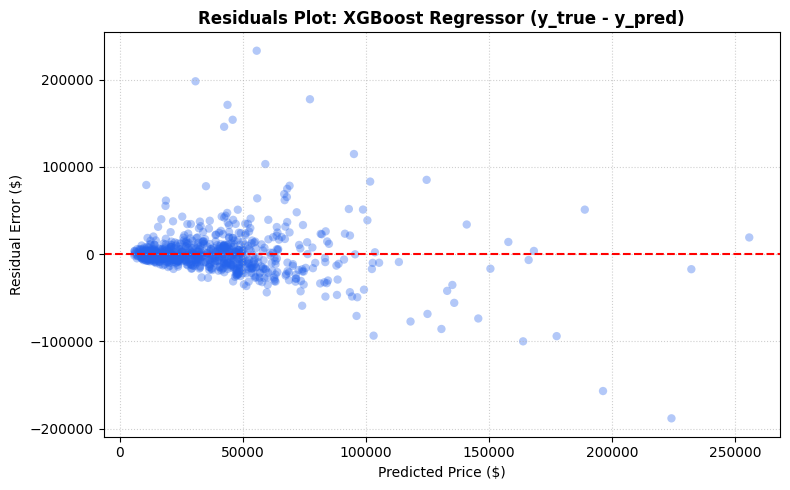

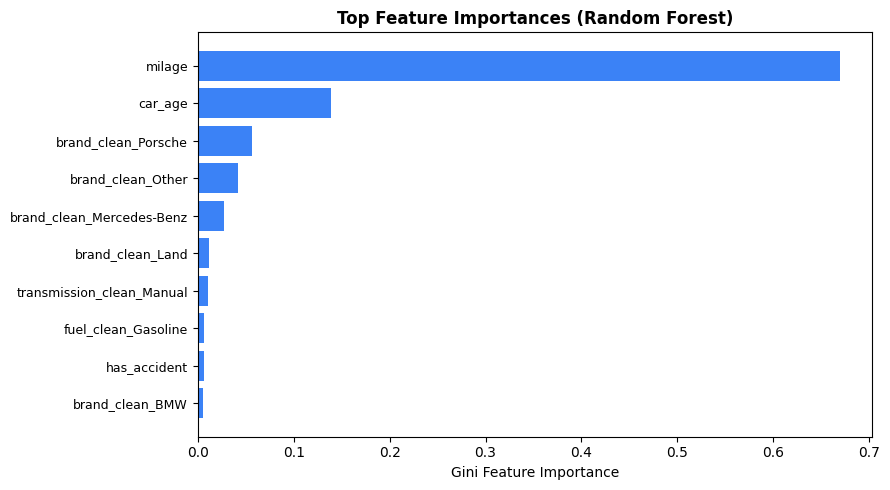


Success! Results table printed and plots saved to the 'assets/' folder.


In [3]:
# ==============================================================
# ES 335: Used Car Price Prediction Pipeline (Full & Cleaned)
# Author: Gouru Prakarsha (Roll: 25110121)
# ==============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. LOAD DATA
df = pd.read_csv("cars.csv")
print(f"Original dataset shape: {df.shape}")

# 2. STRING CLEANING & TYPE CONVERSIONS

# A. Clean 'price' column (remove '$' and ',' then convert to float)
df['price'] = (
    df['price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# B. Clean 'milage' column (remove ' mi.' and ',' then convert to float)
df['milage'] = (
    df['milage']
    .astype(str)
    .str.replace(' mi.', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['milage'] = pd.to_numeric(df['milage'], errors='coerce')

# C. Derive 'car_age' from 'model_year' (prediction reference year: 2026)
df['model_year'] = pd.to_numeric(df['model_year'], errors='coerce')
df['car_age'] = 2026 - df['model_year']

# D. Feature Engineering: Accident history indicator
df['has_accident'] = df['accident'].apply(
    lambda x: 1 if isinstance(x, str) and 'accident' in x.lower() else 0
)

# E. Simplify transmission into clean categories (Automatic vs Manual)
def clean_transmission(val):
    if pd.isna(val):
        return 'Automatic'
    val_lower = str(val).lower()
    if 'manual' in val_lower or 'm/t' in val_lower:
        return 'Manual'
    return 'Automatic'

df['transmission_clean'] = df['transmission'].apply(clean_transmission)

# F. Simplify fuel type
def clean_fuel(val):
    if pd.isna(val):
        return 'Gasoline'
    val_lower = str(val).lower()
    if 'gas' in val_lower:
        return 'Gasoline'
    elif 'hybrid' in val_lower:
        return 'Hybrid'
    elif 'electric' in val_lower:
        return 'Electric'
    elif 'diesel' in val_lower:
        return 'Diesel'
    elif 'flex' in val_lower or 'e85' in val_lower:
        return 'Flex Fuel'
    return 'Other'

df['fuel_clean'] = df['fuel_type'].apply(clean_fuel)

# 3. FILTER OUT INVALID ENTRIES & OUTLIERS
# Remove missing targets or prices under $1,000 (scrap/salvage/typos)
df = df.dropna(subset=['price', 'milage', 'car_age'])
df = df[(df['price'] >= 1000) & (df['price'] <= 350000)]
df = df[(df['milage'] >= 0) & (df['milage'] <= 350000)]
df = df[(df['car_age'] >= 0) & (df['car_age'] <= 35)]

# Group rare brands to avoid high-cardinality noise
top_brands = df['brand'].value_counts().nlargest(15).index
df['brand_clean'] = df['brand'].apply(lambda x: x if x in top_brands else 'Other')

print(f"Cleaned dataset shape: {df.shape}")

# 4. SELECT FEATURES & SPLIT (STRICT NO-LEAKAGE PROTOCOL)
feature_cols = ['brand_clean', 'car_age', 'milage', 'fuel_clean', 'transmission_clean', 'has_accident']
X = df[feature_cols]
y = df['price']

# Split 80% Train, 20% Holdout Test BEFORE any scaling or encoding
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Training set: {len(X_train)} samples | Test set: {len(X_test)} samples")

# 5. PREPROCESSING PIPELINE
numeric_features = ['car_age', 'milage']
categorical_features = ['brand_clean', 'fuel_clean', 'transmission_clean']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # keeps 'has_accident' as a 0/1 binary feature
)

# 6. DEFINE BASELINES AND CANDIDATE MODELS
models = {
    "Dummy Baseline (Mean)": DummyRegressor(strategy="mean"),
    "Simple Linear (Mileage only)": Pipeline([
        ('prep', ColumnTransformer([('num', StandardScaler(), ['milage'])])),
        ('reg', LinearRegression())
    ]),
    "Ridge Regression (L2)": Pipeline([
        ('prep', preprocessor),
        ('reg', Ridge(alpha=10.0))
    ]),
    "Random Forest Regressor": Pipeline([
        ('prep', preprocessor),
        ('reg', RandomForestRegressor(n_estimators=120, max_depth=12, random_state=42, n_jobs=-1))
    ])
}

# Add XGBoost if available
try:
    import xgboost as xgb
    models["XGBoost Regressor"] = Pipeline([
        ('prep', preprocessor),
        ('reg', xgb.XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.08, random_state=42))
    ])
except ImportError:
    pass

# 7. FIT AND EVALUATE MODELS
results = {}
predictions = {}

for name, model in models.items():
    if "Mileage only" in name:
        model.fit(X_train[['milage']], y_train)
        y_pred = model.predict(X_test[['milage']])
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    results[name] = {
        "MAE ($)": round(float(mae), 2),
        "RMSE ($)": round(float(rmse), 2),
        "R2 Score": round(float(r2), 4),
        "MAPE (%)": round(float(mape), 2)
    }

results_df = pd.DataFrame(results).T
print("\n" + "="*50)
print("FINAL TEST EVALUATION RESULTS:")
print("="*50)
print(results_df)

# 8. GENERATE AND SAVE ARTIFACTS FOR WEBSITE
os.makedirs("assets", exist_ok=True)

# Plot 1: Residual Plot for Best Tree Model
best_name = "XGBoost Regressor" if "XGBoost Regressor" in predictions else "Random Forest Regressor"
residuals = y_test - predictions[best_name]

plt.figure(figsize=(8, 5))
plt.scatter(predictions[best_name], residuals, alpha=0.35, color='#2563eb', edgecolor='none')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title(f"Residuals Plot: {best_name} (y_true - y_pred)", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Price ($)", fontsize=10)
plt.ylabel("Residual Error ($)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("assets/residuals_plot.png", dpi=200)
plt.show()

# Plot 2: Feature Importances
rf_step = models["Random Forest Regressor"].named_steps['reg']
prep_step = models["Random Forest Regressor"].named_steps['prep']
cat_names = list(prep_step.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feat_names = numeric_features + cat_names + ['has_accident']
importances = rf_step.feature_importances_

top_k = min(10, len(importances))
top_indices = np.argsort(importances)[-top_k:]

plt.figure(figsize=(9, 5))
plt.barh(range(top_k), importances[top_indices], color='#3b82f6')
plt.yticks(range(top_k), [all_feat_names[i] for i in top_indices], fontsize=9)
plt.xlabel("Gini Feature Importance", fontsize=10)
plt.title("Top Feature Importances (Random Forest)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("assets/feature_importance.png", dpi=200)
plt.show()

# Save metrics JSON for the website
with open("metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nSuccess! Results table printed and plots saved to the 'assets/' folder.")

In [4]:
from google.colab import files

# This will automatically trigger a download of both plot images directly to your Downloads folder!
files.download('assets/residuals_plot.png')
files.download('assets/feature_importance.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>